# 01 - Nettoyage des données
Dans ce notebook, on prend le dataset brut (déjà corrigé du bug de concaténation
kilométrage/année) et produit un dataset propre, prêt pour l'analyse (EDA)
et la modélisation.

**Entrée** : `data/raw/used_car_ads_km_fixed.csv`
**Sortie** : `data/cleaned/used_car_ads_clean.csv`


In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)


## 1. Chargement des données

In [2]:
df = pd.read_csv("../data/raw/used_car_ads_km_fixed.csv")
print(f"Nombre de lignes chargées : {len(df)}")

# suivi du nombre de lignes après chaque opération importante
etapes = {"Dataset brut corrigé": len(df)}
df.head()


Nombre de lignes chargées : 1073


,marque,annee,ville,kilometrage,prix,url_annonce,titre_annonce,date_collecte,km_recovery_status
0,Toyota,2022,Casablanca,120000.0,NaN,https://www.avito.ma/fr/oulfa/voitures_d_occas...,Toyota Hilux Revo,2026-11-17,recovered_from_concat
1,Hyundai,2022,El Jadida,NaN,NaN,https://www.avito.ma/fr/biranzarane/voitures_d...,Hyundai Creta diesel automatique 2022,2026-11-17,concat_remainder_still_implausible
2,Volkswagen,2020,Casablanca,NaN,350000.0,https://www.avito.ma/fr/anfa/voitures_d_occasi...,Volkswagen Golf 8 GTI 2020 dédouanée 2022,2026-11-17,unrecoverable
3,Audi,2016,Tétouan,200.0,NaN,https://www.avito.ma/fr/t%C3%A9touan/voitures_...,Audi A3 S-line Diesel Berline Diesel,2026-11-17,recovered_from_concat
4,NaN,2022,Casablanca,25000.0,NaN,https://www.avito.ma/fr/sidi_bernoussi/voiture...,dfsk .k01h,2026-11-17,recovered_from_concat


## 2. État des lieux avant nettoyage

On regarde d'abord ce qu'on a réellement, colonne par colonne, avant de
décider quoi faire. Pas de nettoyage à l'aveugle.


In [3]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum())
print()
print("Répartition du statut de récupération du kilométrage :")
print(df["km_recovery_status"].value_counts())


Valeurs manquantes par colonne :
marque                259
annee                   0
ville                   0
kilometrage           210
prix                  424
url_annonce             0
titre_annonce           0
date_collecte           0
km_recovery_status      0
dtype: int64

Répartition du statut de récupération du kilométrage :
km_recovery_status
recovered_from_concat                 840
concat_remainder_still_implausible    121
unrecoverable                          78
already_valid                          23
missing_originally                      7
concat_empty_remainder                  4
Name: count, dtype: int64


In [4]:
print("Plage des années :", df["annee"].min(), "-", df["annee"].max())
print()
print("Statistiques du prix (non manquant) :")
print(df["prix"].describe())
print()
print("Statistiques du kilométrage (non manquant) :")
print(df["kilometrage"].describe())


Plage des années : 1980 - 2026

Statistiques du prix (non manquant) :
count    6.490000e+02
mean     2.622763e+05
std      2.066119e+05
min      3.000000e+03
25%      1.400000e+05
50%      2.100000e+05
75%      3.100000e+05
max      1.850000e+06
Name: prix, dtype: float64

Statistiques du kilométrage (non manquant) :
count       863.000000
mean     101364.987254
std       73041.558597
min           0.000000
25%       43575.000000
50%      100000.000000
75%      141500.000000
max      500000.000000
Name: kilometrage, dtype: float64


## 3. Décision : lignes sans prix

prix est la variable cible de la régression. Une ligne sans prix
est inutilisable pour cette tâche. On les supprime ici pour le dataset
"modélisation", mais on documente le nombre retiré pour le rapport final.

Note : si on décide plus tard de garder certaines lignes sans prix pour
le clustering (M5), on pourra repartir du fichier `km_fixed` original
plutôt que de ce dataset nettoyé.


In [5]:
n_avant = len(df)
n_sans_prix = df["prix"].isna().sum()

df = df.dropna(subset=["prix"]).copy()

print(f"Lignes avant : {n_avant}")
print(f"Lignes supprimées (prix manquant) : {n_sans_prix}")
print(f"Lignes restantes : {len(df)}")
etapes["Après suppression des prix manquants"] = len(df)


Lignes avant : 1073
Lignes supprimées (prix manquant) : 424
Lignes restantes : 649


## 4. Décision : kilométrage non récupérable

Le script de correction a déjà séparé les lignes en catégories. On ne
garde que celles où le kilométrage est fiable (`recovered_from_concat`
ou `already_valid`). Les autres sont mises à `NaN` plutôt que de garder
une valeur inventée.


In [6]:
print("Répartition du statut (sur les lignes avec prix) :")
print(df["km_recovery_status"].value_counts())


Répartition du statut (sur les lignes avec prix) :
km_recovery_status
recovered_from_concat                 532
concat_remainder_still_implausible     60
unrecoverable                          35
already_valid                          13
missing_originally                      5
concat_empty_remainder                  4
Name: count, dtype: int64


In [7]:
# on garde la colonne kilometrage telle quelle (déjà NaN pour les cas
# non récupérables grâce au script de correction) ; on retire juste la
# colonne de diagnostic qui ne sert plus
df = df.drop(columns=["km_recovery_status"])

print(f"Kilométrage manquant après nettoyage : {df['kilometrage'].isna().sum()} / {len(df)}")


Kilométrage manquant après nettoyage : 104 / 649


## 5. Décision : marque manquante

`marque` est manquante pour une partie des annonces. Comme `titre_annonce`
est toujours présent, on tente de récupérer la marque en cherchant les
noms de marques connues dans le titre, avant d'abandonner les lignes
encore sans marque.


**Constat à l'exécution** : la recherche littérale des marques connues ne
récupère quasiment rien, car les titres utilisent des alias (« Mercedes »,
« VW », « Range Rover »), uniquement le modèle (« Golf », « Clio »,
« Touareg ») ou des marques absentes de la colonne `marque` (Jaguar, Cupra,
Lexus, DS…). On ajoute donc, en second recours, un dictionnaire explicite
d'alias / modèles → marque canonique (motifs délimités par `\b` pour éviter
les faux positifs). Les nouvelles marques sont de vraies marques présentes
sur le marché marocain : on les garde comme catégories à part entière.

In [8]:
print(f"Marque manquante avant récupération : {df['marque'].isna().sum()}")
print()
print("Exemples de titres sans marque :")
print(df[df["marque"].isna()]["titre_annonce"].head(15).to_string())


Marque manquante avant récupération : 148

Exemples de titres sans marque :
14       Mercedes Classe A 220 AMG Plus dédouanée 2026
15                                   Fiorino climatisé
17           DS 7 Diesel Automatique 2022 à Casablanca
20                                     oulfa haj fatah
23               Cupra Formentor Performance PRIX FIXE
30    Chery Tiggo 2 Pro 2022 – Essence – Très bon état
37                           Rare Jaguar XJ6 limousine
38                                      Classe E 220 d
43                          Touran Rline 190ch 7places
45                                Mercedes classe C200
49             Maserati Ghibli Diesel Automatique 2015
54           P 308 HDI 130 CH Allure Automatique Carat
55                                Jaguar XF excellente
56                         A220d AMG Line Premium Plus
64      Lexus NX Hybride Automatique 2021 à Casablanca


In [9]:
# Liste des marques déjà vues dans le dataset (triée par longueur
# décroissante pour matcher les noms composés en premier, ex. "Land Rover"
# avant "Rover" s'il existait)
marques_connues = sorted(df["marque"].dropna().unique(), key=len, reverse=True)

# Motifs (regex, insensibles à la casse) recherchés dans le titre quand
# aucune marque connue n'y figure littéralement. Ordre = priorité.
ALIAS_MARQUES = {
    # marques réelles absentes de la colonne marque
    r"\bcupra\b": "Cupra",
    r"\bjaguar\b": "Jaguar",
    r"\bmaserati\b": "Maserati",
    r"\blexus\b": "Lexus",
    r"\bcadillac\b": "Cadillac",
    r"\bbyd\b": "BYD",
    r"\bchery\b": "Chery",
    r"\bgwm\b": "GWM",
    r"\bgeely\b": "Geely",
    r"\bssangyong\b": "SsangYong",
    r"\bds ?\d\b": "DS",
    r"\bmg ?(\d|zs|hs)\b": "MG",
    # alias / modèles de marques déjà présentes
    r"mercedes|mercides|\bclasse [a-z]\b|\bcl[as]\b|\bgl[abce]\b|\bml \d|\b[acse] ?\d{3}d?\b|\bamg\b": "Mercedes-Benz",
    r"\bvw\b|\bgolf|\btiguan|\btigwan|\btouareg|\bpolo\b|\bpassat\b|\btouran\b|\bt-roc\b": "Volkswagen",
    r"\brange\b": "Land Rover",
    r"\bclio\b|\bm[ée]gane\b|\bcaptur\b|\bkangoo\b|\bkongoo\b|\barkana\b": "Renault",
    r"\blodgy\b|\bsandero\b": "Dacia",
    r"\bp ?308\b|\b3008|\b208\b|\bpeugoet\b": "Peugeot",
    r"\bc[1-5]\b|\bberlingo\b": "Citroën",
    r"\bfiorino\b": "Fiat",
    r"\bmacan\b|\bporsch\b": "Porsche",
    r"\bq[2-8]\b": "Audi",
    r"\bsportage\b": "Kia",
    r"\byaris\b": "Toyota",
    r"\bquasquai\b|\bqashqai\b": "Nissan",
    r"\bcrossland\b|\bopil\b": "Opel",
    r"\balfa rom[ée]o\b": "Alfa Romeo",
}


def retrouver_marque(titre, marque_actuelle):
    if pd.notna(marque_actuelle):
        return marque_actuelle, "colonne marque"
    titre_lower = str(titre).lower()
    for marque in marques_connues:
        if marque.lower() in titre_lower:
            return marque, "marque connue dans le titre"
    for motif, marque in ALIAS_MARQUES.items():
        if re.search(motif, titre_lower):
            return marque, "alias / modèle dans le titre"
    return np.nan, "introuvable"

resultat = df.apply(
    lambda row: retrouver_marque(row["titre_annonce"], row["marque"]),
    axis=1,
    result_type="expand",
)
df["marque"] = resultat[0]

print("Origine de la marque :")
print(resultat[1].value_counts().rename("annonces").to_string(header=False))
print()
print(f"Marque manquante après récupération depuis le titre : {df['marque'].isna().sum()}")

Origine de la marque :
colonne marque                  501
alias / modèle dans le titre    125
introuvable                      23

Marque manquante après récupération depuis le titre : 23


In [10]:
# Lignes où la marque reste introuvable : on les regarde avant de décider
print(df[df["marque"].isna()][["titre_annonce", "url_annonce"]].to_string())


                                                     titre_annonce                                                                                                                                         url_annonce
20                                                 oulfa haj fatah                                                                     https://www.avito.ma/fr/maarif/voitures_d_occasion/oulfa_haj_fatah_59095320.htm
102                                             Meknès Hay En-Naim                                                          https://www.avito.ma/fr/marjane_2/voitures_d_occasion/Mekn%C3%A8s_Hay_En_Naim_59095947.htm
151                                     modèle 11/12/2006 km 67000                                                      https://www.avito.ma/fr/oulfa/voitures_d_occasion/mod%C3%A8le_11_12_2006_km_67000_58969437.htm
217                              Belle voiture disponible à Temara                                              https://www.avito.ma/fr/tema

**Vérification manuelle effectuée** : les titres restants ne contiennent
aucune marque ni modèle identifiable (texte générique « Belle voiture »,
nom de quartier, numéro de téléphone, date…). On les supprime, car `marque`
est une des 4 variables prédictives.

In [11]:
# Décision : on supprime les lignes où la marque reste introuvable,
# car marque est une des 4 variables prédictives du problématique.
n_avant_marque = len(df)
df = df.dropna(subset=["marque"]).copy()
print(f"Lignes supprimées (marque introuvable) : {n_avant_marque - len(df)}")
print(f"Lignes restantes : {len(df)}")
etapes["Après suppression des marques introuvables"] = len(df)


Lignes supprimées (marque introuvable) : 23
Lignes restantes : 626


## 6. Valeurs atypiques (prix, kilométrage)

On examine les distributions et les statistiques descriptives **avant**
toute décision. La règle de Tukey (`[Q1 − 1,5×IQR ; Q3 + 1,5×IQR]`) sert
seulement à repérer des candidats : une valeur hors bornes n'est pas
forcément une erreur (une Porsche à 1,8 M DH est réelle). Chaque cas est
classé en **erreur manifeste**, **extrême plausible** ou **indéterminé**.

In [12]:
def resume_outliers(serie):
    s = serie.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    borne_basse, borne_haute = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({
        "valeurs non manquantes": len(s),
        "valeurs manquantes": serie.isna().sum(),
        "minimum": s.min(),
        "P1": s.quantile(0.01),
        "P5": s.quantile(0.05),
        "Q1": q1,
        "médiane": s.median(),
        "Q3": q3,
        "P95": s.quantile(0.95),
        "P99": s.quantile(0.99),
        "maximum": s.max(),
        "IQR": iqr,
        "borne basse de Tukey": borne_basse,
        "borne haute de Tukey": borne_haute,
        "sous la borne basse": (s < borne_basse).sum(),
        "au-dessus de la borne haute": (s > borne_haute).sum(),
    })

stats_outliers = pd.DataFrame({
    "prix (DH)": resume_outliers(df["prix"]),
    "kilométrage (km)": resume_outliers(df["kilometrage"]),
})
print(f"Statistiques descriptives sur {len(df)} annonces :")
stats_outliers.round(0)

Statistiques descriptives sur 626 annonces :


,prix (DH),kilométrage (km)
valeurs non manquantes,626.0,524.0
valeurs manquantes,0.0,102.0
minimum,3000.0,0.0
P1,36750.0,0.0
P5,78250.0,673.0
Q1,145000.0,65750.0
médiane,210000.0,110000.0
Q3,317250.0,152925.0
P95,647000.0,250000.0
P99,1155000.0,300038.0


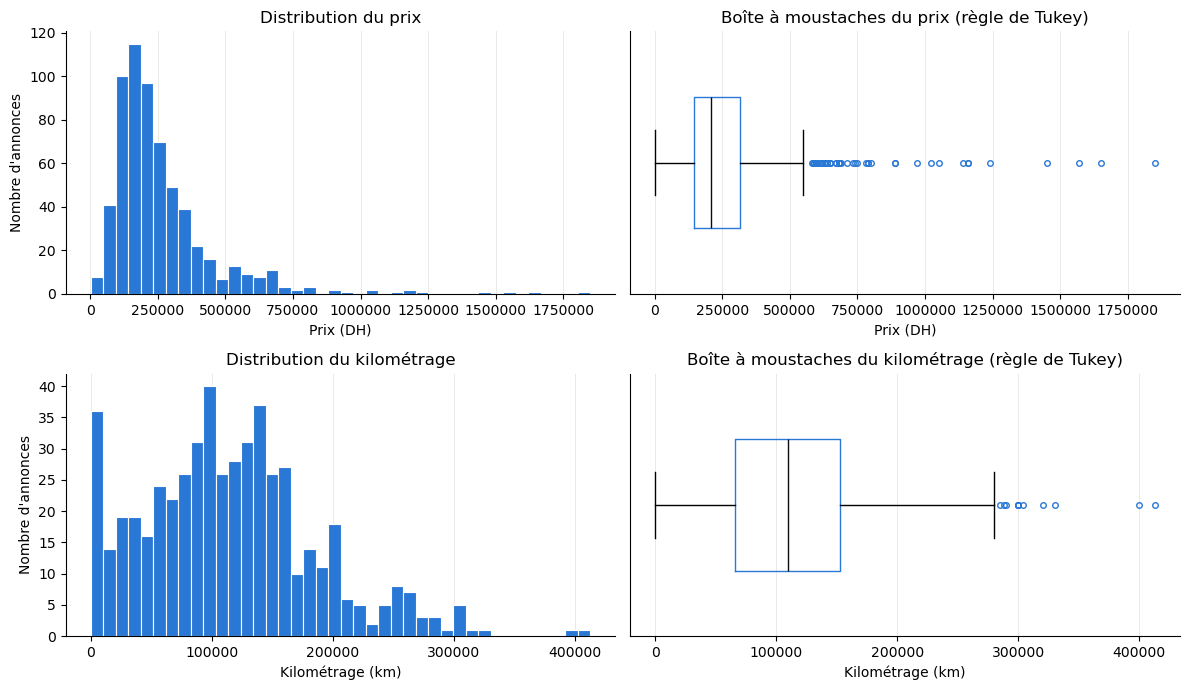

In [13]:
COULEUR = "#2a78d6"

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ligne, (col, unite) in enumerate([("prix", "DH"), ("kilometrage", "km")]):
    s = df[col].dropna()
    ax = axes[ligne, 0]
    ax.hist(s, bins=40, color=COULEUR, edgecolor="white", linewidth=0.8)
    ax.set_title(f"Distribution du {'prix' if col == 'prix' else 'kilométrage'}")
    ax.set_xlabel(f"{'Prix' if col == 'prix' else 'Kilométrage'} ({unite})")
    ax.set_ylabel("Nombre d'annonces")
    ax = axes[ligne, 1]
    ax.boxplot(s, vert=False, widths=0.5,
               boxprops=dict(color=COULEUR), medianprops=dict(color="#0b0b0b"),
               flierprops=dict(marker="o", markersize=4, markeredgecolor=COULEUR))
    ax.set_title(f"Boîte à moustaches du {'prix' if col == 'prix' else 'kilométrage'} (règle de Tukey)")
    ax.set_xlabel(f"{'Prix' if col == 'prix' else 'Kilométrage'} ({unite})")
    ax.set_yticks([])
for ax in axes.flat:
    ax.grid(axis="x", color="#e5e5e2", linewidth=0.6)
    ax.set_axisbelow(True)
    for cote in ("top", "right"):
        ax.spines[cote].set_visible(False)
    ax.ticklabel_format(axis="x", style="plain")
fig.tight_layout()
plt.show()

### 6.1 Prix

On affiche les extrêmes avec le titre pour juger de leur plausibilité.

In [14]:
print("Prix les plus bas :")
print(df.nsmallest(10, "prix")[["marque", "annee", "prix", "titre_annonce", "url_annonce"]].to_string())
print()
print("Prix les plus élevés :")
print(df.nlargest(10, "prix")[["marque", "annee", "prix", "titre_annonce", "url_annonce"]].to_string())


Prix les plus bas :
         marque  annee     prix                                             titre_annonce                                                                                                                               url_annonce
748       Honda   2008   3000.0                     Honda Accord essence 2L dariba 3000dh                                   https://www.avito.ma/fr/ain_atig/voitures_d_occasion/Honda_Accord_essence_2L_dariba_3000dh_59095480.htm
804     Citroën   1995  16000.0             Citroën ZX Essence Manuelle 1995 à Casablanca               https://www.avito.ma/fr/casablanca/voitures_d_occasion/Citro%C3%ABn_ZX_Essence_Manuelle_1995_%C3%A0_Casablanca_59095437.htm
640      Toyota   2022  21500.0                       Toyota CHR hybride 2022 automatique                               https://www.avito.ma/fr/sala_el_jadida/voitures_d_occasion/Toyota_CHR_hybride_2022_automatique_55993296.htm
694        Fiat   2003  28000.0                                     

**Analyse des prix extrêmes**

- **Prix élevés (au-dessus de la borne de Tukey)** : il s'agit presque
  exclusivement de véhicules haut de gamme récents (Porsche Cayenne, Land
  Rover Defender V8, Mercedes-AMG, Cadillac Escalade, Audi Q8…). Des prix
  de 0,7 à 1,85 M DH sont cohérents avec le marché marocain pour ces
  modèles → **extrêmes plausibles, conservés**.
- **Prix bas** : les vieilles voitures (Citroën ZX 1995 à 16 000 DH, Fiat
  Palio 2003 à 28 000 DH…) sont plausibles → **conservées**.
- **Erreurs manifestes** (4 annonces, vérifiées une par une) :
  1. Honda Accord 2008 à 3 000 DH : le titre indique « dariba 3000dh », ce
     qui correspond au montant de la vignette et non au prix du véhicule.
  2. Toyota C-HR hybride 2022 à 21 500 DH : environ 10 fois moins que la
     cote d'un C-HR récent. C'est probablement un acompte, une mensualité
     ou une faute de saisie.
  3. Peugeot 301 2021 à 1 140 000 DH : environ 10 fois plus que la cote
     d'une berline 301. C'est probablement un zéro en trop.
  4. Volkswagen Golf 8 R-Line 2022 à 33 800 DH : environ 10 fois moins que
     la médiane des Volkswagen récentes. Même nature d'erreur que le C-HR.
     Elle n'est visible qu'après la récupération de sa marque.

**Décision** : on supprime uniquement ces 4 annonces, identifiées par leur
URL. On n'applique aucun seuil automatique et aucune winsorisation : les
outliers légitimes sont conservés et l'éventuelle transformation (log du
prix, par exemple) relève de la modélisation (M4).

In [15]:
ERREURS_PRIX = {
    "Honda_Accord_essence_2L_dariba_3000dh_59095480": "prix = montant de la vignette (dariba), pas le prix du véhicule",
    "Toyota_CHR_hybride_2022_automatique_55993296": "21 500 DH pour un C-HR 2022 : environ 10 fois sous la cote",
    "Peugeot_301_59069173": "1 140 000 DH pour une Peugeot 301 2021 : environ 10 fois au-dessus de la cote",
    "R_Line_full_option_59095085": "33 800 DH pour une Golf 8 R-Line 2022 : environ 10 fois sous la cote",
}

masque_erreurs_prix = df["url_annonce"].str.contains("|".join(ERREURS_PRIX), regex=True)
if masque_erreurs_prix.sum() != len(ERREURS_PRIX):
    raise ValueError(
        f"Erreurs de prix attendues : {len(ERREURS_PRIX)}, trouvées : {masque_erreurs_prix.sum()}"
    )

print("Annonces supprimées (erreur de prix manifeste) :")
print(df.loc[masque_erreurs_prix, ["marque", "annee", "prix", "titre_annonce"]].to_string())

n_avant_prix = len(df)
df = df[~masque_erreurs_prix].copy()
print()
print(f"Lignes avant : {n_avant_prix}")
print(f"Lignes supprimées (erreur de prix) : {n_avant_prix - len(df)}")
print(f"Lignes restantes : {len(df)}")
etapes["Après suppression des erreurs de prix"] = len(df)

Annonces supprimées (erreur de prix manifeste) :
         marque  annee       prix                                         titre_annonce
640      Toyota   2022    21500.0                   Toyota CHR hybride 2022 automatique
685     Peugeot   2021  1140000.0                                           Peugeot 301
748       Honda   2008     3000.0                 Honda Accord essence 2L dariba 3000dh
961  Volkswagen   2022    33800.0  Golf 8 modèle 2022 dédouanée 2026 R-Line full option

Lignes avant : 626
Lignes supprimées (erreur de prix) : 4
Lignes restantes : 622


### 6.2 Kilométrage

Le correctif du scraper a déjà borné le kilométrage à `[0 ; 500 000]` km.
Les extrêmes à regarder sont donc surtout les **très faibles valeurs**.

In [16]:
cols = ["marque", "annee", "kilometrage", "prix", "titre_annonce"]
print("Kilométrages les plus faibles :")
print(df.nsmallest(25, "kilometrage")[cols].to_string())
print()
print("Kilométrages les plus élevés :")
print(df.nlargest(10, "kilometrage")[cols].to_string())

Kilométrages les plus faibles :
            marque  annee  kilometrage       prix                                                                   titre_annonce
56   Mercedes-Benz   2026          0.0   710000.0                                                     A220d AMG Line Premium Plus
306        Peugeot   2026          0.0   149000.0                                        Peugeot 208 style essence 1.2 neuve 2026
401          Volvo   2013          0.0   120000.0                                        Volvo XC60 Diesel Manuelle 2013 à Dakhla
567            BYD   2026          0.0   370000.0                                                              BYD SEAL DM-I PLUS
591        Peugeot   2024          0.0   169000.0                                          PEUGEOT 208 DIESEL STYLE 2024 35.000KM
657  Mercedes-Benz   2026          0.0  1160000.0                                              MERCEDES BENZ CLASSE E 300 HYBRIDE
682  Mercedes-Benz   2026          0.0  1160000.0         

**Analyse des kilométrages extrêmes**

- **Valeurs élevées** (300 000 à 413 000 km sur des voitures de 2005 à
  2018, souvent diesel) : elles sont fréquentes au Maroc (taxis, longs
  trajets) → **extrêmes plausibles, conservées**.
- **0 km sur une voiture de 2026** (annonces « neuve ») : plausible →
  **conservé**.
- **Erreurs manifestes** : des kilométrages quasi nuls sur des voitures
  qui ont plusieurs années (0 km pour une Volvo XC60 de 2013, 148 km pour
  une GLC de 2018, 2 000 km pour une Punto de 2011). Plusieurs titres
  contredisent directement la valeur : « 35.000KM » ou « 14.000 KM » pour
  un relevé à 0 km, « 80.700 km » pour un relevé à 700 km, et 668 km qui
  correspond à l'autonomie d'une Kia EV9. Ce sont très probablement des
  valeurs saisies en milliers de km ou des résidus du bug de concaténation.

**Règle appliquée** : le kilométrage est jugé invraisemblable si
`annee ≤ 2025` **et** `kilometrage < 1 000 km`, **ou** si la moyenne
annuelle est inférieure à 500 km/an (même condition `annee ≤ 2025`), avec
un âge calculé comme `2026 − annee` (la collecte date de 2026). Les voitures
de 2026 ne sont jamais concernées : 0 km y est plausible.

**Décision** : on passe la valeur à `NaN` mais on **garde la ligne**, car
le prix, la marque, l'année et la ville restent valides. On ne multiplie
pas par 1 000 et on ne relit pas le titre pour corriger : on ne devine pas,
comme dans le correctif du kilométrage.

**Cas indéterminés conservés** : quelques voitures de 2024-2025 affichent
de 66 000 à 130 000 km, soit plus de 60 000 km/an. C'est inhabituel mais
possible (usage professionnel), donc on les garde.

In [17]:
ANNEE_COLLECTE = 2026
age = (ANNEE_COLLECTE - df["annee"]).clip(lower=1)
km_par_an = df["kilometrage"] / age

masque_km_aberrant = (df["annee"] <= ANNEE_COLLECTE - 1) & (
    (df["kilometrage"] < 1000) | (km_par_an < 500)
)

print(f"Kilométrages jugés invraisemblables : {masque_km_aberrant.sum()}")
print(df.loc[masque_km_aberrant, cols].sort_values("kilometrage").to_string())

n_km_nan_avant = df["kilometrage"].isna().sum()
df.loc[masque_km_aberrant, "kilometrage"] = np.nan
print()
print(f"Kilométrage manquant avant : {n_km_nan_avant} / {len(df)}")
print(f"Kilométrage manquant après : {df['kilometrage'].isna().sum()} / {len(df)}")
print(f"Lignes supprimées : 0 (lignes restantes : {len(df)})")

Kilométrages jugés invraisemblables : 21
            marque  annee  kilometrage      prix                                                                   titre_annonce
401          Volvo   2013          0.0  120000.0                                        Volvo XC60 Diesel Manuelle 2013 à Dakhla
591        Peugeot   2024          0.0  169000.0                                          PEUGEOT 208 DIESEL STYLE 2024 35.000KM
785        Hyundai   2025          0.0  380000.0                                       HYUNDAI TUCSON NLINE (FIN 2025) 14.000 KM
737     Volkswagen   2009          3.0   98000.0                                                    Golf5 2009 diwana 2014 170ch
822           Fiat   2023         60.0  138000.0                                                                Fiat 500 essence
453  Mercedes-Benz   2021         98.0  687000.0                                            Mercides GLE COPIE DIESEL électrique
664        Peugeot   2020        117.0  249000.0        

## 7. Doublons

Aucune URL n'apparaît deux fois. En revanche, certaines annonces sont
re-publiées sous une autre URL, avec les mêmes marque, année, kilométrage,
prix et ville et un titre identique ou quasi identique. On garde la
première occurrence de chaque groupe pour ne pas compter deux fois le même
véhicule.

In [18]:
cles_doublon = ["marque", "annee", "kilometrage", "prix", "ville"]
print(f"Doublons d'URL : {df['url_annonce'].duplicated().sum()}")

masque_groupes = df.duplicated(subset=cles_doublon, keep=False)
print("Groupes de re-publications :")
print(df.loc[masque_groupes, cles_doublon + ["titre_annonce"]].sort_values(cles_doublon).to_string())

n_avant_doublons = len(df)
df = df.drop_duplicates(subset=cles_doublon, keep="first").copy()
print()
print(f"Lignes avant : {n_avant_doublons}")
print(f"Lignes supprimées (doublons) : {n_avant_doublons - len(df)}")
print(f"Lignes restantes : {len(df)}")
etapes["Après suppression des doublons"] = len(df)

Doublons d'URL : 0
Groupes de re-publications :
       marque  annee  kilometrage      prix   ville                                      titre_annonce
223       BMW   2021      98000.0  369000.0  Tanger  BMW X3 PACK M 2021 BVA ÉTAT EXCEPTIONNEL À TANGER
229       BMW   2021      98000.0  369000.0  Tanger  BMW X3 PACK M 2021 BVA ÉTAT EXCEPTIONNEL À TANGER
988   Citroën   2024      99000.0  185000.0     Fès   Citroën C3 Aircross Diesel Automatique PRIX FIXE
1017  Citroën   2024      99000.0  185000.0     Fès   Citroën C3 Aircross automatique diesel PRIX FIXE
623   Peugeot   2026          NaN  215000.0   Rabat          PEUGEOT 208 GT – MODÈLE FIN NOVEMBRE 2025
628   Peugeot   2026          NaN  215000.0   Rabat          PEUGEOT 208 GT – MODÈLE FIN NOVEMBRE 2025

Lignes avant : 622
Lignes supprimées (doublons) : 3
Lignes restantes : 619


## 8. Aperçu final avant sauvegarde

In [19]:
print("Nombre de lignes à chaque étape :")
suivi = pd.DataFrame({"lignes": pd.Series(etapes)})
suivi["supprimées"] = (-suivi["lignes"].diff()).fillna(0).astype(int)
display(suivi)

colonnes_modele = ["annee", "kilometrage", "marque", "ville", "prix"]
manquantes = [c for c in colonnes_modele if c not in df.columns]
if manquantes:
    raise ValueError(f"Colonnes de modélisation absentes : {manquantes}")

print(f"Nombre final de lignes : {len(df)}")
print()
print("Types des colonnes :")
print(df.dtypes.to_string())
print()
print("Valeurs manquantes restantes :")
print(df.isna().sum().to_string())
print()
print(f"Marques distinctes : {df['marque'].nunique()} — villes distinctes : {df['ville'].nunique()}")

Nombre de lignes à chaque étape :


,lignes,supprimées
Dataset brut corrigé,1073,0
Après suppression des prix manquants,649,424
Après suppression des marques introuvables,626,23
Après suppression des erreurs de prix,622,4
Après suppression des doublons,619,3


Nombre final de lignes : 619

Types des colonnes :
marque            object
annee              int64
ville             object
kilometrage      float64
prix             float64
url_annonce       object
titre_annonce     object
date_collecte     object

Valeurs manquantes restantes :
marque             0
annee              0
ville              0
kilometrage      121
prix               0
url_annonce        0
titre_annonce      0
date_collecte      0

Marques distinctes : 39 — villes distinctes : 37


In [20]:
print("Statistiques finales du prix et du kilométrage :")
df[["annee", "prix", "kilometrage"]].describe().round(0)

Statistiques finales du prix et du kilométrage :


,annee,prix,kilometrage
count,619.0,619.0,498.0
mean,2019.0,266270.0,119261.0
std,6.0,205934.0,68870.0
min,1980.0,16000.0,0.0
25%,2017.0,145000.0,70000.0
50%,2021.0,210000.0,113550.0
75%,2023.0,316500.0,155000.0
max,2026.0,1850000.0,413000.0


## 9. Sauvegarde du dataset nettoyé

In [21]:
import os
os.makedirs("../data/cleaned", exist_ok=True)
df.to_csv("../data/cleaned/used_car_ads_clean.csv", index=False)
print("Fichier sauvegardé : data/cleaned/used_car_ads_clean.csv")
print(f"{len(df)} lignes, {df.shape[1]} colonnes")


Fichier sauvegardé : data/cleaned/used_car_ads_clean.csv
619 lignes, 8 colonnes
